In [1]:
import geopops
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as stats
import starsim as ss
import sciris as sc
import geopandas as gpd
from geopandas import GeoDataFrame
from shapely.geometry import Point
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, Image
from measles_geopops import Measles, custom_seeding, plot_measles
import warnings
warnings.resetwarnings()
warnings.filterwarnings(
    "ignore",
    message=r"FNV hashing is not implemented in Numba.*",
    category=UserWarning,
    module=r"numba\.cpython\.hashing")
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module=r"pyproj\..*",
)

# 4.0 Measles and seeding infections
In this notebook, we'll explore the custom measles class and the impact of seeding infections to a selected school. The seeding example uses a base measles model without any isolation or quarantine. These are explored in the next notebook `5_measles_quarantine.ipynb`.

## 4.1 Custom Measles class

Think of this measles example as a starting point of an iterative, community-building modeling exercise. GeoPops and Starsim provide a customizable framework for a detailed, context-specific scenario model, but this version is the first draft! There is still a lot that can be added in collaboration with public health researchers and officials on the ground to make the model more realistic.

Here's a refresher of how Starsim transmission works from previous notebooks:

For each time step, Starsim knows who the infectious agents are (sources) and who the susceptible agents are (targets). For every contact (i.e., edge) between agents, there is a probability of infection every time step if one of those agents is infectious. To calculate that probability, Starsim scales the base infectiousness of the disease by:
* The source’s relative transmissability
* The target’s relative susceptibility
* The effective transmission strength of that contact (edge_weight)

To decide if a target agent gets infected, Starsim draws a uniform random number between 0 and 1 for that contact. If the probability is larger than the random draw, that contact is marked as having caused an infection. So, for each time step we have a list of infectious sources and a list of targets who got infected.

When an agent enters a disease state (e.g., Infectious), Starsim samples and stores the future time that agent will transition out of that state (e.g., using the duration of infection). When that stored time is reached, the agent transitions to the next state (e.g., Recovered).

The custom measles class is called `Measles()` and is stored in `measles_geopops.py` builds on Starsim's base SIR class stored in the Starsim file `diseases.py`. You can customize diseases in many ways (adding disease compartments or subgroup-specific parameters). Our custom measles class includes:
* A state for Exposed individuals
* Age-dependent relative transmissability and relative susceptability
* Reduced susceptibility for vaccinated individuals
* A custom function to seed infections by age and school

Here are the main disease parameters used in `Measles()`:

| Parameter | Definition | Default value |
| -------- | -------- | -------- | 
| beta | Disease's base infectiousness, scaled by rel_trans, rel_sus, and edge_weight to determine probability of infection | 0.3 |
| dur_exp | Duration of Exposed state (not contagious), drawn from normal distribution | 10.0 |
| dur_inf | Duration of Infecitous state (contagious), drawn from normal distribution | 8.0 |
| vax_eff_d1 | Effectiveness after dose 1 of vaccine at reducing susceptibility, scales rel_sus by 1-vax_eff_1, applied to children where age=1 | 0.93 |
| vax_eff_d2 | Effectiveness after dose 2 of vaccine at reducing susceptibility, scales rel_sus by 1-vax_eff_d2, applied to children where age>=2 | 0.97 |
| rel_sus_babies | Relative susceptability of ages <2 | 1.0 |
| rel_sus_young | Relative susceptability of ages 2-4 | 1.0 |
| rel_sus_school | Relative susceptability of ages 5-18 | 1.0 |
| rel_sus_adults | Relative susceptability of ages >18| 0.0 |
| rel_trans_babies | Relative transmissibility of ages <2 | 1.0 |
| rel_trans_young | Relative transmissibility of ages 2-4 | 1.0 |
| rel_trans_school | Relative transmissibility of ages 5-18 | 1.0 |
| rel_trans_adults | Relative transmissibility of ages >18| 0.0 |

To begin, we'll arbitrarily set the base infectiousoness `beta` to be 0.3.

The probability of infection for an exposed *unimunized* 5 year old in our model is therefore 0.3. And the probability of infection for an exposed *imunized* 5 year old is 0.027.
* Unimunized: beta * rel_sus_school * rel_trans_school * edge_weight = 0.3 (0.3 * 1 * 1 * 1 = 0.3)
* Imunized: beta * rel_sus_school * (1 - vax_eff) * rel_trans_school * edge_weight = 0.027 (0.3 * 1 * (1 - 0.97) * 1 * 1 = 0.009)

Note: By default, Starsim does not clamp the probability of transmission to be less than one. The random draw is betwen 0 and 1. This means that a transmission will definitely happen if the product of disease beta, rel_sus, rel_trans, and edge_weight is over 1. Here's a [guide](https://docs.starsim.org/user_guide/advanced_time.html#probability-rates) to Starsim rates and probabilities.

The [CDC](https://www.cdc.gov/measles/hcp/communication-resources/clinical-diagnosis-fact-sheet.html#:~:text=Measles%20is%20a%20highly%20contagious%20respiratory%20virus,more%20than%20104%C2%B0%20F%20when%20rash%20appears) describes the following progression of illness, which informs dur_exp and dur_inf in the model.

| Measles progression | Days | Model compartment |
| -------- | -------- | -------- | 
| Incubation, no symptoms | 1-10 | Exposed |
| Prodromal symptoms, cough/fever | 11-14 | Infectious |
| Rash | 15-18 | Infectious |
| Rash clears |19-21 | Recovered |

To simplify the Spartanburg example, we also assume
* Only children under 18 can get infected, so we set `rel_sus_adults=0` and `rel_trans_adults=0`
* Infections only occur in the home and at school so we don't need to include the work and group quarters networks in the sim
* No one dies from measles, probability of death `p_death` = 0

Initial prevalence is defined with a custom seeding function stored in `measles_geopops.py`. We'll look at adjusting this in following sections of this notebook.

After running the cell below, try changing the parameter values and re-running to see how they change infection curves.

Note: In the plots, "Infectious" refers to the number of agents currently in the infectious state (I), and "cumulative infections" means the cumulative sum of new infections.

In [ ]:

# Load the people object
ppl = ss.load('data/pop_export/starsim/ppl_vax.pkl')

# Define the networks with edge weights. 
# Assuming same relative edge weights but can change if you want to
h = geopops.for_starsim.network(name='homenet', edge_weight=1.0) 
s = geopops.for_starsim.network(name='schoolnet', edge_weight=1.0)

measles_pars = sc.objdict(beta      = 0.5, # disease's base infectiousness (scaled by rel_trans, rel_sus, and edge_weight)
                          dur_exp   = ss.normal(10.0), # duration of exposed state, in this model not infectious, drawn from normal distribution
                          dur_inf   = ss.normal(8.0), # duration of infectious state, drawn from normal distribution
                          p_death   = ss.bernoulli(p=0.0), # probability of death, drawn from Bernoulli distribution
                          vax_eff_d1 = 0.93, # effectiveness of 1 dose (age 1), scales rel_sus by 1-vax_eff_d1
                          vax_eff_d2 = 0.97, # effectiveness of 2 doses (age 2+), scales rel_sus by 1-vax_eff_d2
                          rel_sus_babies   = 1.0, # relative susceptability of ages <2
                          rel_sus_young    = 1.0, # relative susceptability of ages 2-4
                          rel_sus_school   = 1.0, # relative susceptability of ages 5-17    
                          rel_sus_adults   = 0.0, # relative susceptability of ages >18
                          rel_trans_babies = 1.0, # relative transmissability of ages <2
                          rel_trans_young  = 1.0, # relative transmissability of ages 2-4
                          rel_trans_school = 1.0, # relative transmissability of ages 5-17
                          rel_trans_adults = 0.0, # relative transmissability of ages >18
                          )

# Run sim with no quarantine
sim1 = ss.Sim(
    pars    = sc.objdict(start = 0, stop  = 300, dt = 1.0),
    people  = ppl,
    networks = [h, s],
    diseases = [Measles(measles_pars)],  # use custom Measles model
).run()

# Store results
res1 = sim1.results

# Plot results
plot_measles(sim1, res1)

The plot above is created with the `plot_measles()` function, which is defined in `measles_geopops.py`. You can also use Starsim's plotting function or plot one outcome at a time. Keep in mind, with Starsim's default, prevalence uses the entire population (even dummy agents who live outside Spartanburg).

Figure(800x600)


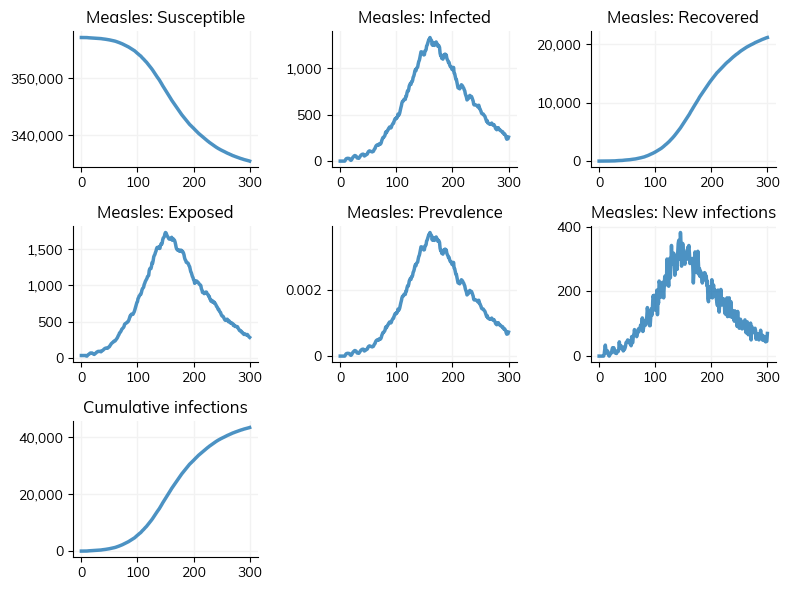

['timevec', 'n_susceptible', 'n_infected', 'n_recovered', 'n_exposed', 'prevalence', 'new_infections', 'cum_infections', 'new_infections_by_network']


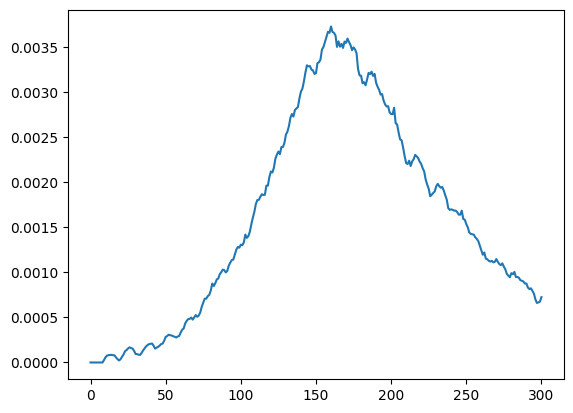

In [5]:
# Starsim's plotting function
sim1.plot()

# Print available outcomes to plot with this disease
# 'n_susceptible', 'n_infected', 'n_recovered', 'n_exposed', 'prevalence', 'new_infections', 'cum_infections', 'new_infections_by_network'
print(res1['measles'].keys()) 

# Plot one outcome at a time
plt.plot(res1['measles'].prevalence)

## 4.2 Seed infections
The first measles infections in Spartanburg were [reported at two schools](https://dph.sc.gov/news/measles-update-dph-confirms-locations-spartanburg-county-outbreak-media-briefing-take-place): Fairforest Elementary (public) and Global Academy of South Carolina (private). GeoPops does not currently include private schools or daycares but will in the future. In this section, we find the school code and CBG of Fairforest Elementary. Then we seed infections to agents attending this chool, run a sim, and plot infected by CBG over time.

### 4.2.1 Find target school
To target a certain school in our seeding function we need its school code, which corresponds to the `sch_code` variable in our people object. We can use the file `EDGE_GEOCODE_PUBLICSCH_[YEAR].xlsx` that was downloaded with `geopops.download_data()` in `1_run_geopops.ipynb`. This file comes from NCES data and has every public school with its name and NCES school code. The variable `NCESSCH` in this file corresponds to the variable `sch_code` in our Starsim people object and in `pop_export/sch_students.csv`, a GeoPops file listing students by school.

In [6]:
# Read in list of public schools and filter for Spartanburg County 
public_schools = pd.read_excel('data/school/EDGE_GEOCODE_PUBLICSCH_1920.xlsx') # big file, takes a while
public_schools = public_schools.loc[(public_schools['CNTY'] == 45083)] # filter for Spartanburg County
public_schools['NAME'].unique() # Print out school names

<ArrowStringArray>
[                                    'Tyger River High',
                         'SC School for the Blind High',
                          'SC School for the Deaf High',
             'SC School for the Deaf Elementary/Middle',
            'SC School for the Blind Elementary/Middle',
                                'Cedar Springs Academy',
             'R. D. Anderson Applied Technology Center',
                         'H. B. Swofford Career Center',
                      'Daniel Morgan Technology Center',
                                       'Landrum Middle',
                           'Campobello-Gramling School',
                               'O. P. Earle Elementary',
                      'Holly Springs-Motlow Elementary',
                                     'Inman Elementary',
                              'New Prospect Elementary',
                                         'Chapman High',
                                         'Landrum High',
            

In [7]:
# Now filter EDGE_GEOCODE_PUBLICSCH_[YEAR]].xlsx for Fairforest Elementary and get it's NCESSCH number which corresponds to sch_code
school_name = 'Fairforest Elementary'
school_info = public_schools.loc[public_schools['NAME'] == school_name]
school_info # Print info for selected school

,NCESSCH,LEAID,NAME,OPSTFIPS,STREET,CITY,STATE,ZIP,STFIP,CNTY,...,NMCBSA,CBSATYPE,CSA,NMCSA,NECTA,NMNECTA,CD,SLDL,SLDU,SCHOOLYEAR
78744,450363001025,4503630,Fairforest Elementary,45,1005 Mount Zion Road,Spartanburg,SC,29303,45,45083,...,"Spartanburg, SC",1,273,"Greenville-Spartanburg-Anderson, SC",N,N,4504,45036,45012,2019-2020


The `sch_code` for Fairforest Elementary is 450363001025. Now let's figure out what CBG that school is located in using the shapefile `tl_[YEAR]_45_bg.shp`, which was already downloaded into the geo folder when you made the GeoPops population in `1_run_geopops.ipynb`. The CBG code is used for plotting later. To find it, we can cross reference the LAT and LON in the `school_info` dataframe with the `geography` column in the shapefile. Copy and paste the school code under `NCESSCH` from the dataframe in the previous cell into `sch_code` below.

In [8]:
school_name = 'Fairforest Elementary'
sch_code = 450363001025  

# Shapefile for CBGs in SC
geo_shp = gpd.read_file('data/geo/tl_2019_45_bg.shp') # This file is already downloaded into geo folder
geo_shp['cbg_geocode'] = geo_shp['GEOID'].astype(int)

# find the CBG for the school
sch_geo = (
    gpd.sjoin(
        gpd.GeoDataFrame(
            school_info.loc[school_info["NCESSCH"] == sch_code],
            geometry=school_info.loc[school_info["NCESSCH"] == sch_code]
                    .apply(lambda r: Point(r["LON"], r["LAT"]), axis=1),
            crs="EPSG:4326",
        ).to_crs(geo_shp.crs),
        geo_shp[["cbg_geocode", "geometry"]],
        how="left",
        predicate="intersects",
    )["cbg_geocode"].iloc[0]
)
print(f'School code of {school_name}:', sch_code)
print(f'CBG of {school_name}:', sch_geo)


School code of Fairforest Elementary: 450363001025
CBG of Fairforest Elementary: 450830228022


### 4.2.2 Custom seeding function
Now we know that the sch_code for Fairforest Elementary is 450363001025 and its CBG is 450830228022. The `custom_seeding()` function is stored in `measles_geopops.py`. Here's the logic: identify agents under `max_age` at school `sch_code` and assign `n_seeds` of them to start the simulation exposed. We limit the age to avoid seeding adult workers or students with infections because in our toy example, adults can't get infected. 

The cell below shows how you can adjust the function to seed infections to different schools. It starts with the default values: max_age=18, sch_codes=[450363001025], and n_seeds=30. Trying adjusting these and see how it changes results. Then, you can go back to section 4.2.1 and try targeting a different school.

In [ ]:
sch_code = 450363001025 # default=450363001025 (Fairforest Elementary)

# Define seeding function with target school, max age, and number of seeds
seeding_fn = custom_seeding(max_age=18, # default=18
                            sch_codes=[sch_code], # defined above            
                            n_seeds=30) # default=30

# Add the seeding function to the measles parameters defined in the beginning of the notebook
measles_pars = sc.objdict(init_prev = ss.bernoulli(p=seeding_fn))

# Run the sim with the seeding function
sim2 = ss.Sim(
    pars    = sc.objdict(start = 0, stop  = 300, dt = 1.0),
    people  = ppl,
    networks = [h,s],
    diseases = [Measles(measles_pars)],
).run()

# Store results
res2 = sim2.results

# Plot the results
plot_measles(sim2, res2,label=f'Seeded infections at {school_name}')

## 4.3 Spatial Spread
We also want to see how seeding infections at different schools impacts spatial spread of the disease. Because we know where each agent lives, we can track infections by geography (down to CBG). The GeoPops function `for_starsim.subgroup_tracking()` allows you to track infections by any of your agent attributes (`agegroup`, `commuter_income_category`, etc.) as long as it is a state in the People object. `subgroup_tracking()` takes the input arguments `subgroup`, `outcome`, and `name`. The `outcome` should be one of the disease compartments, so for measles, it could be `susceptible`, `exposed`, `infected`, or `recovered`. Then you can pass it into a sim as an ss.Analyzer() using the `name`.

In the next cell, we combine the custom seeding function and a `geo_tracking` analyzer into a sim and run it. Then there is a bunch of code to plot an animation of infected by CBG over time. Run the cell making sure that `_sch_geo` (the school's CBG) corresponds to the `sch_code` for your target school. Check out the animation, then try targeting a different school. You can select a school in 4.2.1 or copy and paste from one of these combos.

| school_name | sch_code | sch_geo | n_students | vax_rate | 
| -------- | -------- | -------- | -------- | -------- |
| Fairforest Elementary | 450363001025 | 450830228022 | 939 | 0.82 |
| Landrum Middle | 450348000060 | 450830226002 | 217 | 0.89 |
| Boiling Springs High | 450351001000 | 450830224051 | 1885 | 0.92 |
| Woodruff Elementary | 450357001013 | 450830236004 | 660 | 0.96 |

In [ ]:
school_name = 'Fairforest Elementary'
sch_code = 450363001025
sch_geo  = 450830228022

# Define analyzer to track infections by geography
geo_tracking = geopops.for_starsim.subgroup_tracking(subgroup='cbg_geocode', 
                                                   outcome='infected', 
                                                   name='geo_tracking')

# Define seeding function with target school, max age, and number of seeds
seeding_fn = custom_seeding(max_age=18, # default=18
                            sch_codes=[sch_code], # defined above            
                            n_seeds=30) # default=30

# Add the seeding function to the measles parameters
measles_pars = sc.objdict(init_prev = ss.bernoulli(p=seeding_fn))

# Run sim with analyzer
sim3 = ss.Sim(
    pars    = sc.objdict(start = 0, stop  = 300, dt = 1.0),
    people  = ppl,
    networks = [h,s],
    diseases = [Measles(measles_pars)],
    analyzers = [geo_tracking],
    ).run()

# Store results
res3 = sim3.results

# Plot results
plot_measles(sim3, res3)

### Code for animation ###

# Get population per CBG
ppl_df = sim3.people.to_df() 
ppl_df = ppl_df.groupby('cbg_geocode').size().reset_index()
ppl_df = ppl_df.loc[ppl_df['cbg_geocode'] != 0] # drop dummy agents who live outside the geo area and have cbg_geocode = 0
ppl_df = ppl_df.rename(columns={0: 'pop'})

# Get infected by tract with analyzer
geo_df = sim3.analyzers[0].get_subgroup_data() # Returns second analyzer (cbg_tracking) as dataframe
geo_df = geo_df.loc[geo_df['cbg_geocode'] != 0].set_index('cbg_geocode') # drop dummy agents who live outside the geo area and have cbg_geocode = 0
geo_df = geo_df.merge(ppl_df, on='cbg_geocode', how='left').set_index('cbg_geocode')

# Calculate infected per 1000 population
# for col in geo_df.columns[:-1]:
#     geo_df[col] = geo_df[col] / geo_df['pop'] * 1000
# geo_df.drop(columns=['pop'], inplace=True)

# Get shapefile for CBGs in SC
# This file is already downloaded in into geo folder
geo_shp = gpd.read_file('data/geo/tl_2019_45_bg.shp')
geo_shp['cbg_geocode'] = geo_shp['GEOID'].astype(int)

# Merge with analyzer results
geo_shp = geo_shp.merge(geo_df, on='cbg_geocode', how='left')

# Get centroid of target tract
target_geom = geo_shp.loc[geo_shp['cbg_geocode'] == sch_geo, 'geometry'].iloc[0]
cx, cy = target_geom.centroid.x, target_geom.centroid.y

# Columns you want to animate
cols = list(geo_df.columns[:-1])

# Keep color scale fixed across frames so colors are comparable
vmin = geo_shp[cols].min().min()
vmax = geo_shp[cols].max().max()

fig, ax = plt.subplots(figsize=(10, 6))

def update(frame):
    ax.clear()
    col = cols[frame]

    # Plot current frame
    geo_shp.plot(
        column=col,
        cmap='Blues',
        legend=False,   # avoid stacking a new legend/colorbar every frame
        ax=ax,
        edgecolor='black',
        linewidth=0.5,
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(
        f'Infected by CBG\n{col}',
        fontsize=20,
        fontweight='bold'
    )
    ax.set_xticks([])
    ax.set_yticks([])

    # Add arrow annotation
    ax.annotate(
        text=f'Infections seeded to\n {school_name}',
        xy=(cx, cy),
        xytext=(-0.12, 0.5),         # outside left side of axes
        textcoords='axes fraction',
        arrowprops=dict(arrowstyle='->', color='black', linewidth=1.5),
        fontsize=18,
        ha='right',
        va='center',
        annotation_clip=False
    )

# Draw first frame once so we can make one shared colorbar
geo_shp.plot(
    column=cols[0],
    cmap='Blues',
    legend=True,
    ax=ax,
    edgecolor='black',
    linewidth=0.5,
    vmin=vmin,
    vmax=vmax
)

ax.set_title(
    f'Infected CBG\n{cols[0]}',
    fontsize=20,
    fontweight='bold'
)
ax.set_xticks([])
ax.set_yticks([])

ax.annotate(
    text=f'Infections seeded to\n {school_name}',
    xy=(cx, cy),
    xytext=(-0.12, 0.5),         # outside left side of axes
    textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', color='black', linewidth=1.5),
    fontsize=18,
    ha='right',
    va='center',
    annotation_clip=False
)

# Grab the colorbar axis created by the first plot
cbar = fig.get_axes()[1]
cbar.set_label('Infected')

plt.tight_layout()
plt.close(fig)

ani = FuncAnimation(fig, update, frames=len(cols), interval=100, repeat=True)
ani.save("map_animation.gif", writer="pillow", fps=8)

display(Image("map_animation.gif"))

* **With the current network structure, how do infections spread spatially?** 
* **What's missing from the school network?**
* **What other activities contribute to spatial spread? How could we include them as networks?**

Next notebook: [5_measles_quarantine.ipybn](https://github.com/GeoPopsHub/sc_spartanburg_measles/blob/main/5_measles_quarantine.ipynb)

Previous notebook: [3_explore_networks.ipynb](https://github.com/GeoPopsHub/sc_spartanburg_measles/blob/main/3_explore_networks.ipynb)